In [1]:
import keras

print("Keras backend:", keras.backend.backend())

import tensorflow as tf

print("Available GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1794316555.173368   16831 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794316555.307003   16831 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794316557.006658   16831 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras backend: tensorflow
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1794316559.121770   16831 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [2]:
import pandas as pd

train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("val.csv")
test_df = pd.read_csv("test.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (139780, 14)
Validation: (25676, 14)
Test: (39557, 14)


In [3]:
features = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "motion_mean", "motion_std", "motion_min", "motion_max"
]

X_train = train_df[features]
X_val = val_df[features]

y_train = train_df["stage_4"]
y_val = val_df["stage_4"]

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)

Training: (139780, 8)
Validation: (25676, 8)


# Base NN

In [5]:
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.optimizers import Adam
import keras

keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(8,)),

    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(4, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

W0000 00:00:1794316559.307044   16831 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794316559.418606   16831 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:02:00.0, compute capability: 12.0a
E0000 00:00:1794316559.477933   16831 cuda_executor.cc:1365] [0] Failed to allocate device memory of 9.00GiB (9664724992 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:45
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:230
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:487

E0000 00:00:1794316559.479065   16831 cuda_executor.cc:1365] [0] Failed to allocate device memory of 8.10GiB (869825

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,788 (10.89 KB)

 Trainable params: 2,788 (10.89 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
from keras.callbacks import EarlyStopping
import time

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

start = time.time()

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=256,
    callbacks=[early_stop]
)

print(f"\nTraining time: {time.time() - start:.2f} seconds")

Epoch 1/100


I0000 00:00:1794316563.171614   16945 service.cc:154] XLA service 0x7bd1e4527210 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794316563.171683   16945 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5070, Compute Capability 12.0a (Driver: 13.3.0[610.88.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1794316563.218574   16945 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794316564.076339   17037 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_4', 32 bytes spill stores, 32 bytes spill loads



  1/547 ━━━━━━━━━━━━━━━━━━━━ 35:06 4s/step - accuracy: 0.2734 - loss: 1.4042

I0000 00:00:1794316566.532697   16945 cuda_dnn.cc:442] Loaded cuDNN version 92700
I0000 00:00:1794316566.680456   16945 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


547/547 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4497 - loss: 1.2184

I0000 00:00:1794316569.657706   17884 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 8 bytes spill stores, 8 bytes spill loads



547/547 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.4497 - loss: 1.2184 - val_accuracy: 0.4648 - val_loss: 1.1879
Epoch 2/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4566 - loss: 1.1999 - val_accuracy: 0.4632 - val_loss: 1.1826
Epoch 3/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4586 - loss: 1.1958 - val_accuracy: 0.4659 - val_loss: 1.1803
Epoch 4/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4597 - loss: 1.1939 - val_accuracy: 0.4659 - val_loss: 1.1766
Epoch 5/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4605 - loss: 1.1918 - val_accuracy: 0.4641 - val_loss: 1.1761
Epoch 6/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4608 - loss: 1.1900 - val_accuracy: 0.4640 - val_loss: 1.1743
Epoch 7/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4606 - loss: 1.1891 - val_accuracy: 0.4649 - val_loss: 1.1720
Epoch 8/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4620 - loss: 1.1881 - val_accuracy: 0.4656

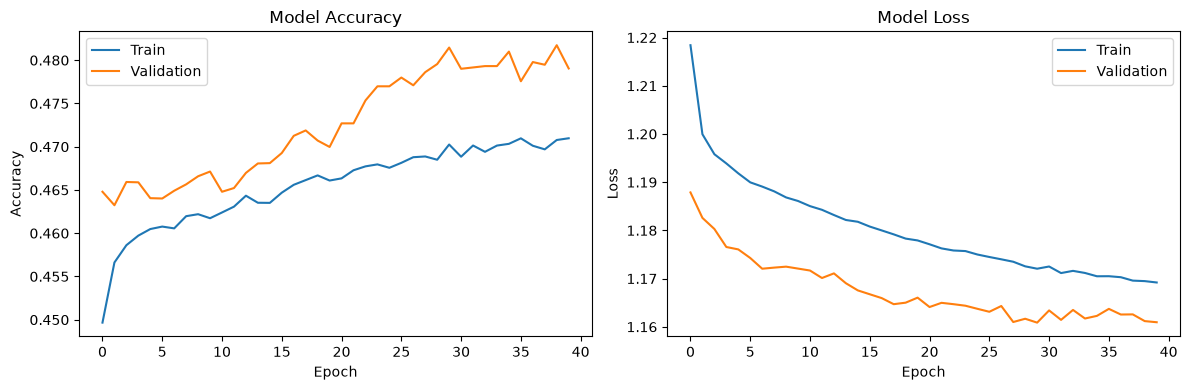

Best epoch: 30


In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

best_epoch = history.history['val_loss'].index(
    min(history.history['val_loss'])
) + 1

print("Best epoch:", best_epoch)

In [8]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Predict validation probabilities
y_val_prob_nn = model.predict(X_val_scaled)

# Convert probabilities to predicted classes
y_val_pred_nn = np.argmax(y_val_prob_nn, axis=1)

# Calculate accuracy
accuracy_nn = accuracy_score(y_val, y_val_pred_nn)

print(f"Validation Accuracy: {accuracy_nn:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_nn,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

803/803 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Validation Accuracy: 48.15%

Classification Report:
              precision    recall  f1-score   support

        Wake       0.65      0.28      0.39      2760
       Light       0.48      0.89      0.62     11731
        Deep       0.49      0.11      0.17      4687
         REM       0.40      0.11      0.17      6498

    accuracy                           0.48     25676
   macro avg       0.50      0.35      0.34     25676
weighted avg       0.48      0.48      0.40     25676



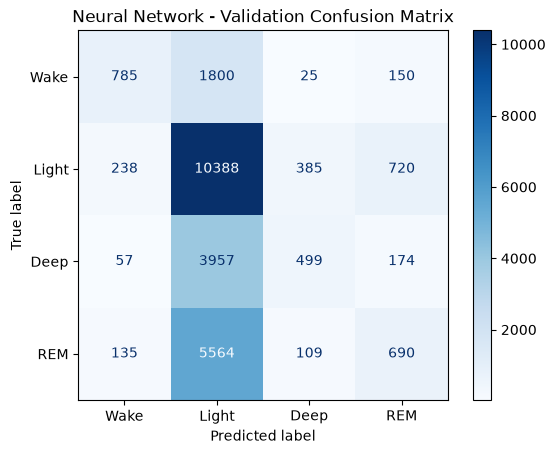

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_nn,
    labels=[0, 1, 2, 3],
    display_labels=["Wake", "Light", "Deep", "REM"],
    cmap="Blues",
    values_format="d"
)

plt.title("Neural Network - Validation Confusion Matrix")
plt.show()

# Adding Class Weights

In [10]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes.astype(int), weights))

print("Class Weights:")
for stage, weight in class_weights.items():
    print(f"Stage {stage}: {weight:.3f}")

Class Weights:
Stage 0: 2.339
Stage 1: 0.566
Stage 2: 1.319
Stage 3: 0.955


In [11]:
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
import time

keras.utils.set_random_seed(42)

# New model with the same architecture
model_weighted = Sequential([
    Input(shape=(8,)),

    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(4, activation='softmax')
])

model_weighted.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

start = time.time()

history_weighted = model_weighted.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=256,
    callbacks=[early_stop],
    class_weight=class_weights
)

print(f"\nTraining time: {time.time() - start:.2f} seconds")

Epoch 1/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3447 - loss: 1.3095 - val_accuracy: 0.3786 - val_loss: 1.3030
Epoch 2/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3498 - loss: 1.2891 - val_accuracy: 0.3827 - val_loss: 1.2912
Epoch 3/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3487 - loss: 1.2836 - val_accuracy: 0.3840 - val_loss: 1.2901
Epoch 4/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3500 - loss: 1.2812 - val_accuracy: 0.3865 - val_loss: 1.2870
Epoch 5/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3509 - loss: 1.2780 - val_accuracy: 0.3882 - val_loss: 1.2821
Epoch 6/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3517 - loss: 1.2760 - val_accuracy: 0.3850 - val_loss: 1.2810
Epoch 7/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3517 - loss: 1.2746 - val_accuracy: 0.3904 - val_loss: 1.2787
Epoch 8/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3533 - loss: 1.2730 - val_accu

In [12]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Predict validation data
y_val_prob_weighted = model_weighted.predict(X_val_scaled)

y_val_pred_weighted = np.argmax(
    y_val_prob_weighted, axis=1
)

# Accuracy
accuracy_weighted = accuracy_score(
    y_val, y_val_pred_weighted
)

print(f"Validation Accuracy: {accuracy_weighted:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_weighted,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

803/803 ━━━━━━━━━━━━━━━━━━━━ 1s 886us/step
Validation Accuracy: 39.97%

Classification Report:
              precision    recall  f1-score   support

        Wake       0.35      0.57      0.43      2760
       Light       0.56      0.31      0.40     11731
        Deep       0.32      0.55      0.40      4687
         REM       0.37      0.38      0.37      6498

    accuracy                           0.40     25676
   macro avg       0.40      0.45      0.40     25676
weighted avg       0.45      0.40      0.40     25676



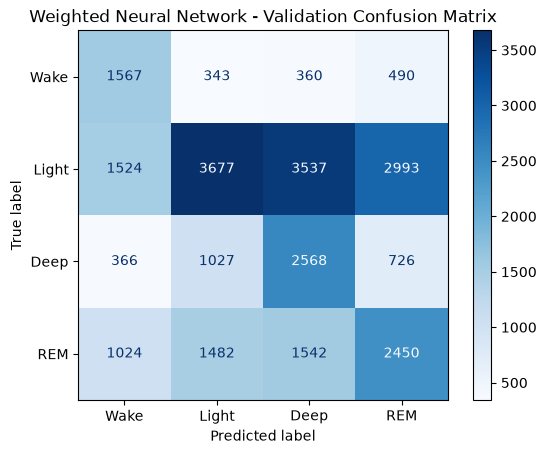

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_weighted,
    labels=[0, 1, 2, 3],
    display_labels=["Wake", "Light", "Deep", "REM"],
    cmap="Blues",
    values_format="d"
)

plt.title("Weighted Neural Network - Validation Confusion Matrix")
plt.show()

# Soft Class Weights

In [14]:
# Softer class weights
soft_weights = {
    stage: weight ** 0.5
    for stage, weight in class_weights.items()
}

keras.utils.set_random_seed(42)

model_soft = Sequential([
    Input(shape=(8,)),

    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(4, activation='softmax')
])

model_soft.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

start = time.time()

history_soft = model_soft.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=256,
    callbacks=[early_stop],
    class_weight=soft_weights
)

print(f"Training time: {time.time() - start:.2f} seconds")

Epoch 1/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4304 - loss: 1.2493 - val_accuracy: 0.4426 - val_loss: 1.2147
Epoch 2/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4342 - loss: 1.2318 - val_accuracy: 0.4465 - val_loss: 1.2071
Epoch 3/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4365 - loss: 1.2273 - val_accuracy: 0.4505 - val_loss: 1.2049
Epoch 4/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4371 - loss: 1.2248 - val_accuracy: 0.4547 - val_loss: 1.2006
Epoch 5/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4376 - loss: 1.2224 - val_accuracy: 0.4535 - val_loss: 1.2006
Epoch 6/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4398 - loss: 1.2205 - val_accuracy: 0.4541 - val_loss: 1.1986
Epoch 7/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4411 - loss: 1.2196 - val_accuracy: 0.4570 - val_loss: 1.1977
Epoch 8/100
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4417 - loss: 1.2183 - val_accu

In [15]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Predict validation data
y_val_prob_soft = model_soft.predict(X_val_scaled)

# Convert probabilities to class predictions
y_val_pred_soft = np.argmax(y_val_prob_soft, axis=1)

# Calculate accuracy
accuracy_soft = accuracy_score(y_val, y_val_pred_soft)

print(f"Validation Accuracy: {accuracy_soft:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_soft,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

803/803 ━━━━━━━━━━━━━━━━━━━━ 1s 916us/step
Validation Accuracy: 46.97%

Classification Report:
              precision    recall  f1-score   support

        Wake       0.51      0.42      0.46      2760
       Light       0.51      0.68      0.58     11731
        Deep       0.39      0.26      0.31      4687
         REM       0.37      0.26      0.31      6498

    accuracy                           0.47     25676
   macro avg       0.44      0.40      0.41     25676
weighted avg       0.45      0.47      0.45     25676



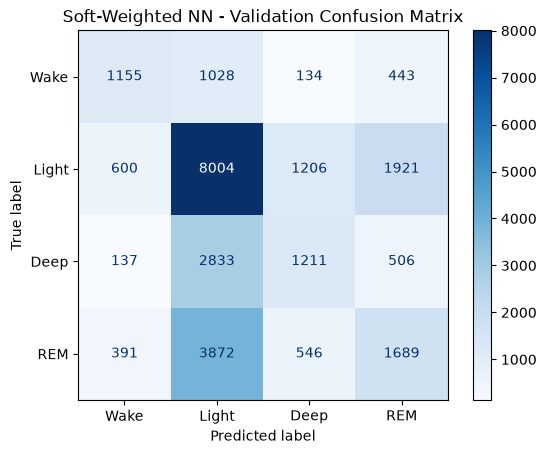

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_soft,
    labels=[0, 1, 2, 3],
    display_labels=["Wake", "Light", "Deep", "REM"],
    cmap="Blues",
    values_format="d"
)

plt.title("Soft-Weighted NN - Validation Confusion Matrix")
plt.show()

In [17]:
import joblib

model_soft.save("sleep_nn_soft.keras")
joblib.dump(scaler, "sleep_scaler.pkl")

['sleep_scaler.pkl']